# ML Assignment 2 - Heartbeat Classification (PTB ECG data)

### **Name: Kanishk Kunal**  
### **BITS ID: 2026AK05570**  

Dataset - https://www.kaggle.com/datasets/shayanfazeli/heartbeat (only the PTB part, `ptbdb_normal.csv` and `ptbdb_abnormal.csv`)

The idea is to predict if a heartbeat is normal or abnormal from the ECG signal.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

## 1. Loading the data

In [2]:
normal = pd.read_csv("data/ptbdb_normal.csv", header=None)
abnormal = pd.read_csv("data/ptbdb_abnormal.csv", header=None)

print("normal file:", normal.shape)
print("abnormal file:", abnormal.shape)

normal file: (4046, 188)
abnormal file: (10506, 188)


In [3]:
normal.head()

,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,1.000000,0.900324,0.358590,0.051459,0.046596,0.126823,0.133306,0.119125,0.110616,0.113047,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.000000,0.794681,0.375387,0.116883,0.000000,0.171923,0.283859,0.293754,0.325912,0.345083,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.909029,0.791482,0.423169,0.186712,0.000000,0.007836,0.063032,0.077002,0.074957,0.077342,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.000000,0.478893,0.056760,0.064176,0.081289,0.072732,0.055619,0.048774,0.054478,0.041643,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.000000,0.867238,0.201360,0.099349,0.141336,0.120934,0.108516,0.096393,0.093436,0.100828,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


No header in the files, so pandas just named the columns 0 to 187. Checking that the last column is the label:

In [4]:
print(normal[187].unique())
print(abnormal[187].unique())

[0.]
[1.]


0 = normal and 1 = abnormal. 
Combining both into one dataframe and giving the columns proper names.

In [5]:
df = pd.concat([normal, abnormal], ignore_index=True)
df.columns = [f"f{i}" for i in range(187)] + ["target"]
df["target"] = df["target"].astype(int)
print(df.shape)

(14552, 188)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14552 entries, 0 to 14551
Columns: 188 entries, f0 to target
dtypes: float64(187), int64(1)
memory usage: 20.9 MB


In [7]:
# just looking at the first few columns, all 187 is too much to see
df.describe().T.head(10)

,count,mean,std,min,25%,50%,75%,max
f0,14552.0,0.976637,0.034532,0.624227,0.959377,1.000000,1.000000,1.000000
f1,14552.0,0.721663,0.195690,0.000000,0.584589,0.740148,0.881483,1.000000
f2,14552.0,0.403099,0.249794,0.000000,0.212300,0.371911,0.557785,1.000000
f3,14552.0,0.242893,0.249519,0.000000,0.052269,0.168148,0.336232,1.000000
f4,14552.0,0.207218,0.218097,0.000000,0.061875,0.136082,0.264104,1.000000
f5,14552.0,0.216453,0.192412,0.000000,0.090487,0.159451,0.264633,1.000000
f6,14552.0,0.221752,0.180740,0.000000,0.096503,0.167479,0.286484,1.000000
f7,14552.0,0.224486,0.176943,0.000000,0.097095,0.171541,0.302255,0.985523
f8,14552.0,0.227349,0.176674,0.000000,0.097231,0.177380,0.311664,0.993213
f9,14552.0,0.229704,0.176579,0.000000,0.097144,0.180337,0.325292,0.997738


In [8]:
print("missing values:", df.isnull().sum().sum())
print("duplicate rows:", df.duplicated().sum())

missing values: 0


duplicate rows: 7


In [9]:
# few duplicates, removing them so the same beat doesnt end up in both train and test
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

(14545, 188)


## 2. EDA

target
1    10500
0     4045
Name: count, dtype: int64


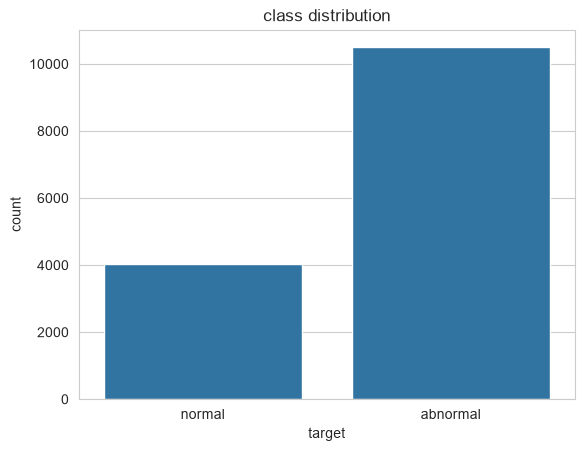

In [10]:
print(df["target"].value_counts())

sns.countplot(x="target", data=df)
plt.xticks([0, 1], ["normal", "abnormal"])
plt.title("class distribution")
plt.show()

Around 72% abnormal and 28% normal, so the data is imbalanced. A model that always says abnormal would already get ~72% accuracy, so we will look more at F1 and MCC than at accuracy.

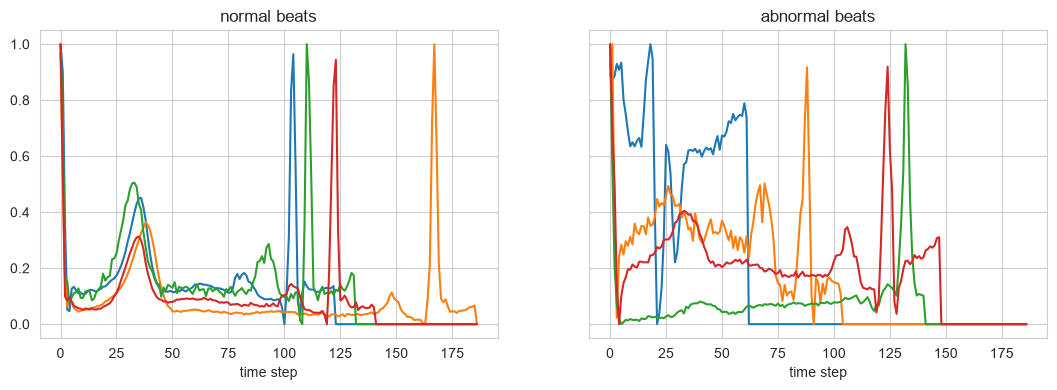

In [11]:
# few random beats from each class
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for i in range(4):
    axes[0].plot(normal.iloc[i * 500, :187].values)
    axes[1].plot(abnormal.iloc[i * 500, :187].values)
axes[0].set_title("normal beats")
axes[1].set_title("abnormal beats")
axes[0].set_xlabel("time step")
axes[1].set_xlabel("time step")
plt.show()

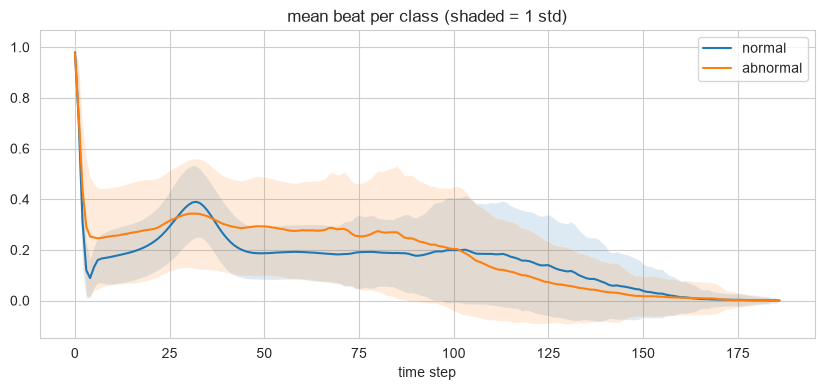

In [12]:
# average beat of each class
features = [f"f{i}" for i in range(187)]
plt.figure(figsize=(10, 4))
for label, name in [(0, "normal"), (1, "abnormal")]:
    mean = df[df["target"] == label][features].mean().values
    std = df[df["target"] == label][features].std().values
    plt.plot(mean, label=name)
    plt.fill_between(range(187), mean - std, mean + std, alpha=0.15)
plt.legend()
plt.title("mean beat per class (shaded = 1 std)")
plt.xlabel("time step")
plt.show()

The beats are zero padded at the end so all rows are 187 long. Wanted to see if the actual length of the beat (before padding starts) is different for the two classes.

          count       mean        std   min    25%    50%    75%    max
target                                                                 
0        4045.0  130.43288  20.653032  62.0  117.0  130.0  145.0  186.0
1       10500.0  112.64381  24.768516  51.0   97.0  110.0  128.0  186.0


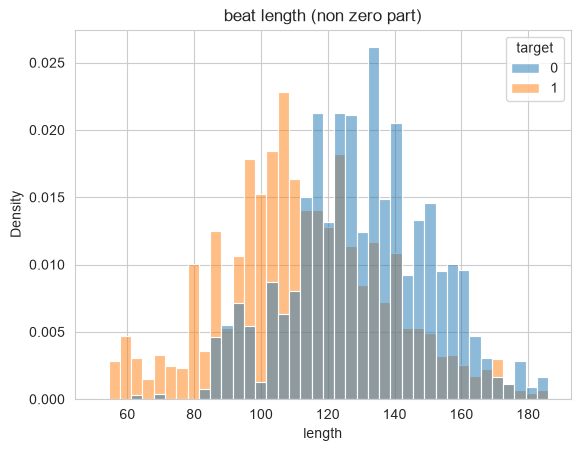

In [ ]:
def beat_length(row):
    nonzero = np.flatnonzero(row)
    return nonzero[-1] + 1


df["length"] = df[features].apply(lambda r: beat_length(r.values), axis=1)
print(df.groupby("target")["length"].describe())

sns.histplot(
    data=df, x="length", hue="target", bins=40, stat="density", common_norm=False
)
plt.title("beat length (non zero part)")
plt.show()

Abnormal beats are shorter on average (~113 vs ~130 samples, at 125 Hz thats around 0.9 s vs 1.04 s), but the two distributions overlap a lot so length alone wont separate them. 

I'm not adding this as a feature, Dropping the lenght column

In [14]:
df = df.drop(columns="length")

## 3. Train / test split

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=21
)

print("train:", X_train.shape, " test:", X_test.shape)
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

train: (11636, 187)  test: (2909, 187)
target
1    0.722
0    0.278
Name: proportion, dtype: float64
target
1    0.722
0    0.278
Name: proportion, dtype: float64


Stratify worked, same ratio in both. Saving the test part now since that is the file to upload in the streamlit app.

In [16]:
test_df = X_test.copy()
test_df["target"] = y_test
test_df.to_csv("test_data.csv", index=False)
print("saved test_data.csv", test_df.shape)

saved test_data.csv (2909, 188)


## 4. Models

### 4.1 Logistic Regression
Scaling the features first. Using a Pipeline so the scaler is saved inside the model file and the app doesnt need a separate scaler.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, matthews_corrcoef

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
lr.fit(X_train, y_train)

print("train acc:", accuracy_score(y_train, lr.predict(X_train)))
print("test acc:", accuracy_score(y_test, lr.predict(X_test)))
print("test mcc:", matthews_corrcoef(y_test, lr.predict(X_test)))

train acc: 0.8368855276727398
test acc: 0.8222756961155037
test mcc: 0.5371971549799986


Data is imbalanced so trying `class_weight='balanced'` to see if it helps.

In [ ]:
lr_bal = make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")
)
lr_bal.fit(X_train, y_train)

print("test acc:", accuracy_score(y_test, lr_bal.predict(X_test)))
print("test mcc:", matthews_corrcoef(y_test, lr_bal.predict(X_test)))

test acc: 0.7813681677552423
test mcc: 0.5364348851246908


Accuracy drops and MCC is basically the same, so balanced doesnt really help. Keeping the normal one.

Since I need the same 6 metrics for every model, writing a function for it instead of repeating the code each time.

In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)


def get_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "AUC": roc_auc_score(y_true, y_prob),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }


results = {}
models = {}


def evaluate(name, model):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]  # probability of abnormal
    scores = get_metrics(y_test, pred, prob)
    results[name] = scores
    models[name] = model
    for k, v in scores.items():
        print(f"{k:10s}: {v:.4f}")
    print()
    print(classification_report(y_test, pred, target_names=["normal", "abnormal"]))

In [20]:
evaluate("Logistic Regression", lr)

Accuracy  : 0.8223
AUC       : 0.8755
Precision : 0.8538
Recall    : 0.9095
F1        : 0.8808
MCC       : 0.5372

              precision    recall  f1-score   support

      normal       0.72      0.60      0.65       809
    abnormal       0.85      0.91      0.88      2100

    accuracy                           0.82      2909
   macro avg       0.79      0.75      0.77      2909
weighted avg       0.82      0.82      0.82      2909



Recall for abnormal is good but a lot of normal beats get predicted as abnormal (normal recall is low). Probably the boundary between the classes is not linear.

### 4.2 Decision Tree
Trees dont need scaling. Starting with the default settings.

In [21]:
from sklearn.tree import DecisionTreeClassifier

dt_default = DecisionTreeClassifier(random_state=21)
dt_default.fit(X_train, y_train)

print("depth:", dt_default.get_depth(), " leaves:", dt_default.get_n_leaves())
print("train acc:", accuracy_score(y_train, dt_default.predict(X_train)))
print("test acc:", accuracy_score(y_test, dt_default.predict(X_test)))

depth: 28  leaves: 452
train acc: 1.0
test acc: 0.9367480233757305


Train accuracy is 1.0, so the tree has just memorised the train data. Checking different `max_depth` values with 5-fold cross validation on the train set (not using the test set for this).

max_depth = 3 -> 0.7717


max_depth = 5 -> 0.8364


max_depth = 8 -> 0.8879


max_depth = 10 -> 0.9043


max_depth = 12 -> 0.908


max_depth = 15 -> 0.9151


max_depth = 20 -> 0.9154


max_depth = 25 -> 0.9151


max_depth = None -> 0.9159


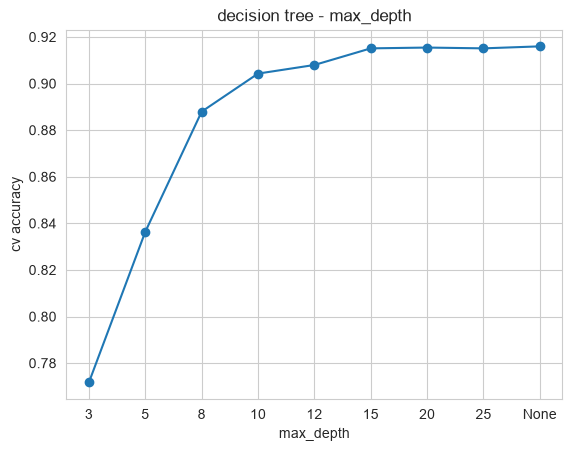

In [ ]:
from sklearn.model_selection import cross_val_score

depths = [3, 5, 8, 10, 12, 15, 20, 25, None]
dt_scores = []
for d in depths:
    score = cross_val_score(
        DecisionTreeClassifier(max_depth=d, random_state=21), X_train, y_train, cv=5
    ).mean()
    dt_scores.append(score)
    print("max_depth =", d, "->", round(score, 4))

plt.plot([str(d) for d in depths], dt_scores, marker="o")
plt.xlabel("max_depth")
plt.ylabel("cv accuracy")
plt.title("decision tree - max_depth")
plt.show()

It keeps improving up to around 15 and after that its flat. So going with `max_depth=15`. Same score as the full tree but a bit smaller.

In [23]:
dt = DecisionTreeClassifier(max_depth=15, random_state=21)
dt.fit(X_train, y_train)
print("train acc:", accuracy_score(y_train, dt.predict(X_train)))
evaluate("Decision Tree", dt)

train acc: 0.9875386730835338
Accuracy  : 0.9292
AUC       : 0.9171
Precision : 0.9584
Recall    : 0.9429
F1        : 0.9506
MCC       : 0.8262

              precision    recall  f1-score   support

      normal       0.86      0.89      0.88       809
    abnormal       0.96      0.94      0.95      2100

    accuracy                           0.93      2909
   macro avg       0.91      0.92      0.91      2909
weighted avg       0.93      0.93      0.93      2909



The test accuracy is a little lower than the full tree from before (0.929 vs 0.937), but I picked the depth using CV on the train set and not the test set, so keeping 15. The difference is small anyway.

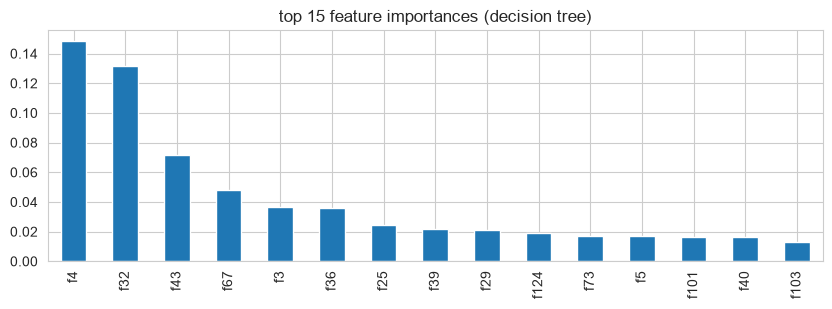

In [ ]:
# which time steps the tree uses the most
imp = pd.Series(dt.feature_importances_, index=X_train.columns).sort_values(
    ascending=False
)
imp.head(15).plot(kind="bar", figsize=(10, 3))
plt.title("top 15 feature importances (decision tree)")
plt.show()

### 4.3 KNN
KNN works on distances, so scaling is needed here too. Trying different k values with cross validation.

k = 1 -> 0.9361


k = 3 -> 0.9242


k = 5 -> 0.9129


k = 7 -> 0.9035


k = 9 -> 0.9006


k = 11 -> 0.8941


k = 15 -> 0.8857


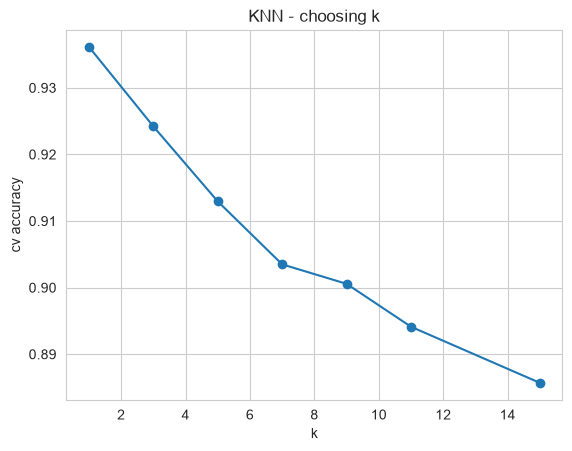

In [25]:
from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 7, 9, 11, 15]
knn_scores = []
for k in k_values:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    score = cross_val_score(pipe, X_train, y_train, cv=5).mean()
    knn_scores.append(score)
    print("k =", k, "->", round(score, 4))

plt.plot(k_values, knn_scores, marker="o")
plt.xlabel("k")
plt.ylabel("cv accuracy")
plt.title("KNN - choosing k")
plt.show()

k=1 has the best accuracy but I dont want to use it. With k=1 the predict_proba is only ever 0 or 1, so the AUC gets worse, and one noisy neighbour decides everything. k=3 is almost as good, so going with k=3.

In [26]:
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3))
knn.fit(X_train, y_train)
evaluate("KNN", knn)

Accuracy  : 0.9343
AUC       : 0.9724
Precision : 0.9609
Recall    : 0.9476
F1        : 0.9542
MCC       : 0.8385

              precision    recall  f1-score   support

      normal       0.87      0.90      0.88       809
    abnormal       0.96      0.95      0.95      2100

    accuracy                           0.93      2909
   macro avg       0.91      0.92      0.92      2909
weighted avg       0.94      0.93      0.93      2909



### 4.4 Naive Bayes
The assignment allows Gaussian or Multinomial. The features are continuous values between 0 and 1, so Gaussian makes more sense, but Multinomial also works with non-negative values so I'm trying both.

In [ ]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB

for nb_model in [GaussianNB(), MultinomialNB()]:
    nb_model.fit(X_train, y_train)
    p = nb_model.predict(X_test)
    print(
        type(nb_model).__name__,
        " acc:",
        round(accuracy_score(y_test, p), 4),
        " f1:",
        round(f1_score(y_test, p), 4),
        " mcc:",
        round(matthews_corrcoef(y_test, p), 4),
    )

GaussianNB  acc: 0.6091  f1: 0.6597  mcc: 0.3197
MultinomialNB  acc: 0.7191  f1: 0.8005  mcc: 0.3286


Both are pretty weak. Multinomial looks better on accuracy and F1, but thats mostly because it predicts "abnormal" much more often (the majority class). The MCC is almost the same for both (0.32 vs 0.33). Going with GaussianNB since the features are continuous signal values and not counts, which is what Multinomial is meant for.

In [28]:
nb = GaussianNB()
nb.fit(X_train, y_train)
evaluate("Naive Bayes", nb)

Accuracy  : 0.6091
AUC       : 0.7655
Precision : 0.8880
Recall    : 0.5248
F1        : 0.6597
MCC       : 0.3197

              precision    recall  f1-score   support

      normal       0.40      0.83      0.54       809
    abnormal       0.89      0.52      0.66      2100

    accuracy                           0.61      2909
   macro avg       0.64      0.68      0.60      2909
weighted avg       0.75      0.61      0.63      2909



### 4.5 SVM
RBF kernel with scaling. First checking the C value with cross validation. Using plain SVC here and only 3 folds because SVM is slow.

In [29]:
from sklearn.svm import SVC

c_scores = {}
for C in [0.1, 1, 10, 50]:
    pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=C))
    c_scores[C] = cross_val_score(pipe, X_train, y_train, cv=3).mean()
    print("C =", C, "->", round(c_scores[C], 4))

best_C = max(c_scores, key=c_scores.get)
print("best C:", best_C)

C = 0.1 -> 0.8147


C = 1 -> 0.9095


C = 10 -> 0.9507


C = 50 -> 0.9626
best C: 50


Higher C works better here, so the model needs a more flexible boundary. 50 was the biggest I tried, and I didnt go higher because each run gets slower and the train/test gap is checked later anyway.

For AUC I need probabilities, and SVC doesnt give them directly. `SVC(probability=True)` gives a deprecation warning in my sklearn version (1.9), and the warning says to use `CalibratedClassifierCV` instead, so doing that.

In [ ]:
from sklearn.calibration import CalibratedClassifierCV

svm = make_pipeline(
    StandardScaler(),
    CalibratedClassifierCV(SVC(kernel="rbf", C=best_C), ensemble=False),
)
svm.fit(X_train, y_train)
print("train acc:", accuracy_score(y_train, svm.predict(X_train)))
evaluate("SVM", svm)

train acc: 0.9938982468202131


Accuracy  : 0.9656
AUC       : 0.9907
Precision : 0.9766
Recall    : 0.9757
F1        : 0.9762
MCC       : 0.9145

              precision    recall  f1-score   support

      normal       0.94      0.94      0.94       809
    abnormal       0.98      0.98      0.98      2100

    accuracy                           0.97      2909
   macro avg       0.96      0.96      0.96      2909
weighted avg       0.97      0.97      0.97      2909



## 5. Comparing all models

In [31]:
results_df = pd.DataFrame(results).T.round(4)
results_df

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.8223,0.8755,0.8538,0.9095,0.8808,0.5372
Decision Tree,0.9292,0.9171,0.9584,0.9429,0.9506,0.8262
KNN,0.9343,0.9724,0.9609,0.9476,0.9542,0.8385
Naive Bayes,0.6091,0.7655,0.8880,0.5248,0.6597,0.3197
SVM,0.9656,0.9907,0.9766,0.9757,0.9762,0.9145


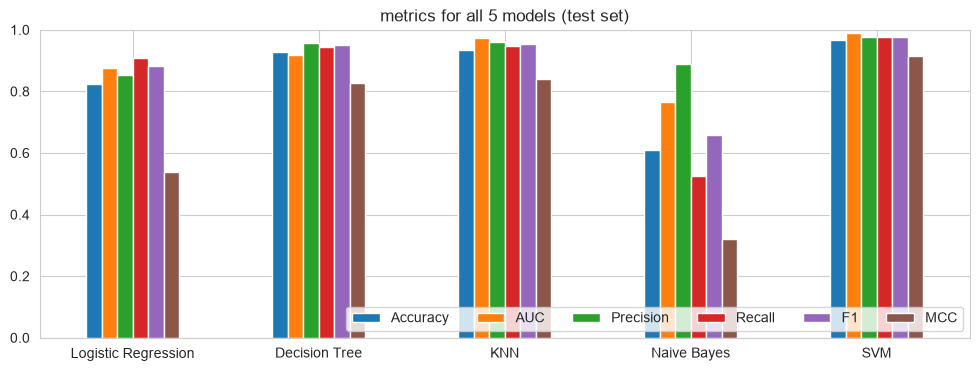

In [32]:
results_df.plot(kind="bar", figsize=(12, 4), rot=0)
plt.ylim(0, 1)
plt.legend(loc="lower right", ncol=6)
plt.title("metrics for all 5 models (test set)")
plt.show()

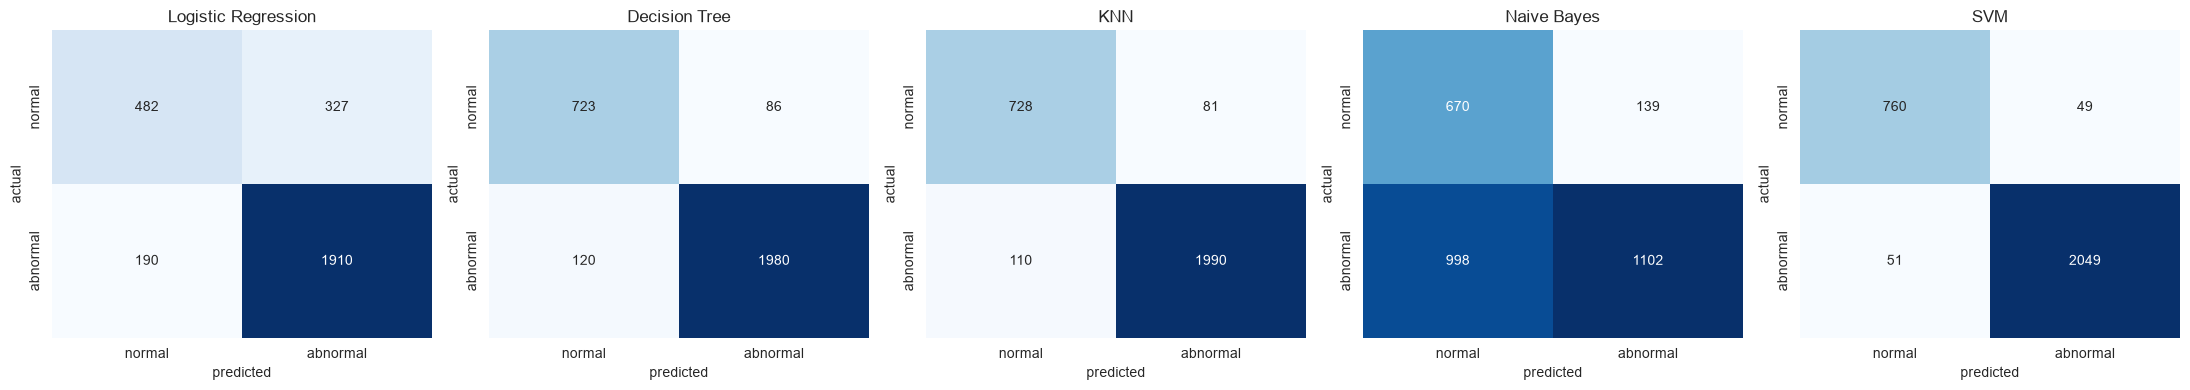

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,
        xticklabels=["normal", "abnormal"],
        yticklabels=["normal", "abnormal"],
    )
    ax.set_title(name)
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
plt.tight_layout()
plt.show()

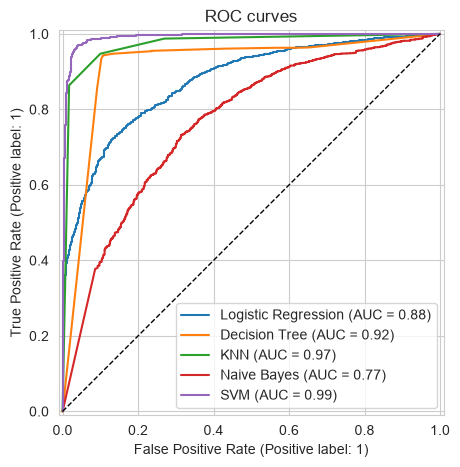

In [34]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 5))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.title("ROC curves")
plt.show()

In [ ]:
# train vs test accuracy to check overfitting
overfit = pd.DataFrame(
    {
        "train acc": {
            n: accuracy_score(y_train, m.predict(X_train)) for n, m in models.items()
        },
        "test acc": {
            n: accuracy_score(y_test, m.predict(X_test)) for n, m in models.items()
        },
    }
).round(4)
overfit["gap"] = overfit["train acc"] - overfit["test acc"]
overfit

,train acc,test acc,gap
Logistic Regression,0.8369,0.8223,0.0146
Decision Tree,0.9875,0.9292,0.0583
KNN,0.9698,0.9343,0.0355
Naive Bayes,0.6137,0.6091,0.0046
SVM,0.9939,0.9656,0.0283


## 6. Saving the models

In [ ]:
import joblib

os.makedirs("model", exist_ok=True)
for name, model in models.items():
    file_name = name.lower().replace(" ", "_") + ".pkl"
    joblib.dump(model, os.path.join("model", file_name))
    print(
        "saved",
        file_name,
        "-",
        round(os.path.getsize(os.path.join("model", file_name)) / 1e6, 2),
        "MB",
    )

saved logistic_regression.pkl - 0.01 MB
saved decision_tree.pkl - 0.06 MB
saved knn.pkl - 17.51 MB
saved naive_bayes.pkl - 0.01 MB
saved svm.pkl - 3.47 MB


In [37]:
# checking that a saved model loads back and gives the same result
loaded = joblib.load("model/svm.pkl")
check = pd.read_csv("test_data.csv")
print(accuracy_score(check["target"], loaded.predict(check.drop(columns="target"))))

0.9656239257476796


## Conclusion
- **SVM** (RBF kernel, C=50) is the best model on every metric: accuracy ~0.97, AUC ~0.99, MCC ~0.91.
- KNN and Decision Tree come next (MCC ~0.83-0.84). KNN has the better AUC of the two.
- Logistic Regression gets a lot of normal beats wrong, so a linear model is not enough for this data.
- Naive Bayes is the worst. Neighbouring time steps of the signal are strongly correlated, so the independence assumption doesnt hold.
- The decision tree has the biggest train/test gap, so it still overfits a bit even with max_depth=15.